In [1]:
!mamba install pandas numpy matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 1.901 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ pandas        3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ six           1.17.0   pyhe01879c_1         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x
- pip           26.2.2   pyh145f28c_0         conda-forge


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from IPython.display import FileLink

# Generates a clickable download link in the output cell
FileLink("retail_sales_dataset.csv")

/drive/retail_sales_dataset.csv

# Fetching data and performing initial inspection

In [4]:
file_path ="retail_sales_dataset.csv"
file_path

'retail_sales_dataset.csv'

In [27]:
df = pd.read_csv(file_path)
df

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100
...,...,...,...,...,...,...,...,...,...
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.columns
df.info()

Rows: 1000
Columns: 9
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 54.8 KB


In [7]:
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [8]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [9]:
df.describe()

,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


# Descriptive Statistics for Numerical Variables

In [10]:
# Descriptive Statistics for Numerical Variables
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']

desc_stats = pd.DataFrame({
    'Mean': df[num_cols].mean().round(2),
    'Median': df[num_cols].median().round(2),
    'Mode': df[num_cols].mode().iloc[0],
    'Std Dev': df[num_cols].std().round(2)
})
print(desc_stats)

                  Mean  Median  Mode  Std Dev
Age              41.39    42.0  43.0    13.68
Quantity          2.51     3.0   4.0     1.13
Price per Unit  179.89    50.0  50.0   189.68
Total Amount    456.00   135.0  50.0   560.00


# Time series analysis

#### Monthly Revenue Trend

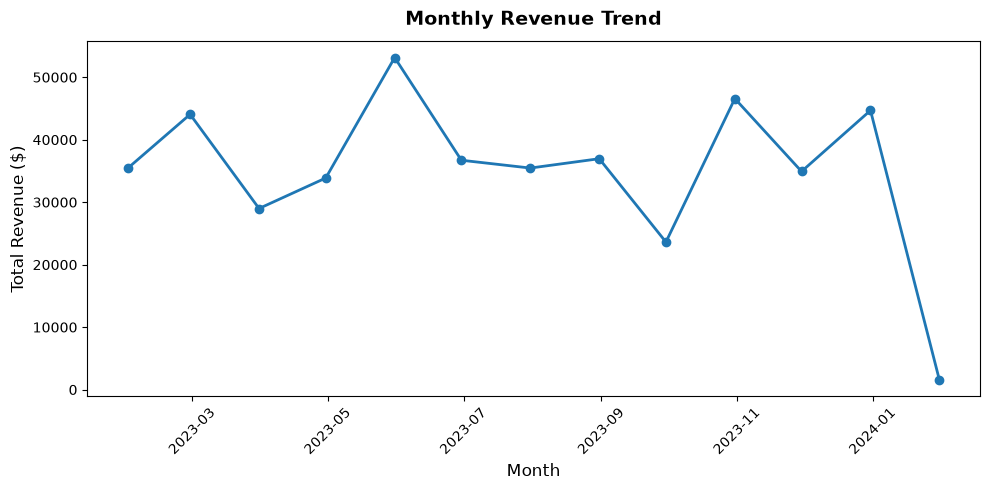

In [31]:
df['Date'] = pd.to_datetime(df['Date'])
df_monthly = df.resample('ME', on='Date')['Total Amount'].sum().reset_index()
plt.figure(figsize=(10, 5))
plt.plot(df_monthly['Date'], df_monthly['Total Amount'], marker='o', color='#1f77b4', linewidth=2)
plt.title('Monthly Revenue Trend', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Quarterly Revenue Trend

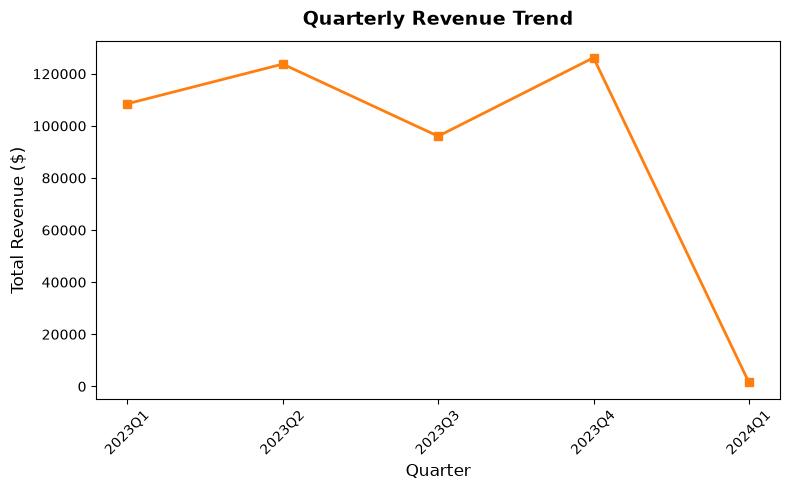

In [32]:
df_quaterly= df.resample('QE', on='Date')['Total Amount'].sum().reset_index()
plt.figure(figsize=(8, 5))
plt.plot(df_quaterly['Date'].dt.to_period('Q').astype(str), df_quaterly['Total Amount'], marker='s', color='#ff7f0e', linewidth=2)
plt.title('Quarterly Revenue Trend', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Quarter', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Customer demographics analysis

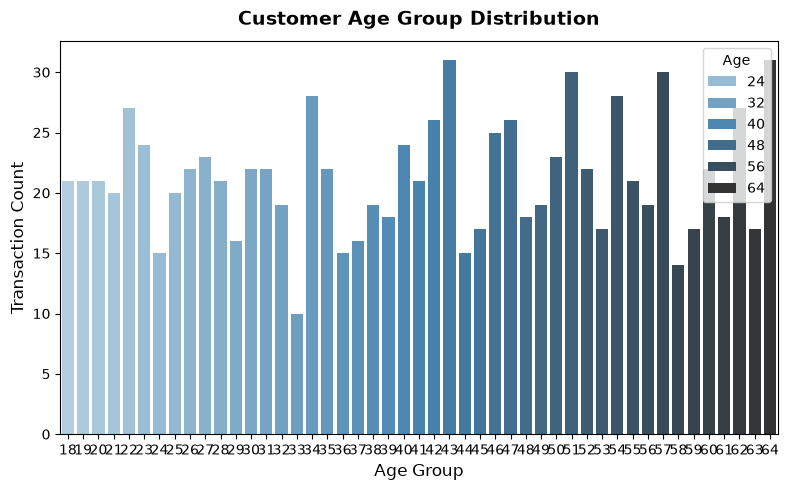

In [33]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df.dropna(subset=['Age']), x='Age', palette='Blues_d', hue='Age')
plt.title('Customer Age Group Distribution', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Transaction Count', fontsize=12)
plt.tight_layout()
plt.show()

#### Gender Breakdown Pie Chart

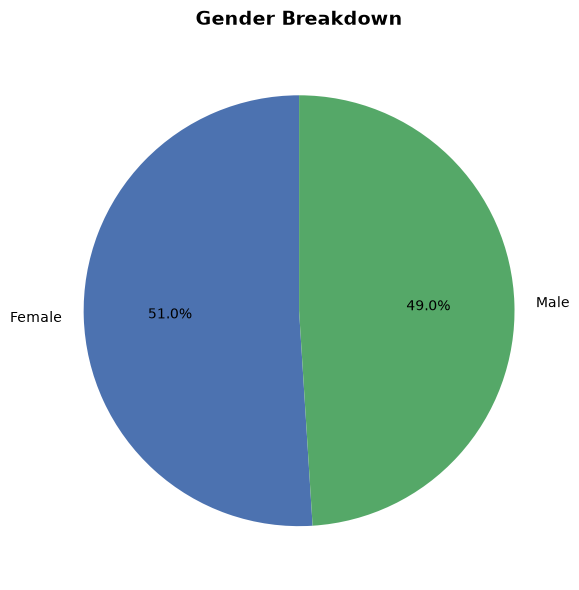

In [34]:
gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', colors=['#4c72b0', '#55a868', '#c44e52'], startangle=90)
plt.title('Gender Breakdown', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('gender_breakdown.png', dpi=300)
plt.show()

# Product analysis

#### Top 10 Best-Selling Products Bar Chart

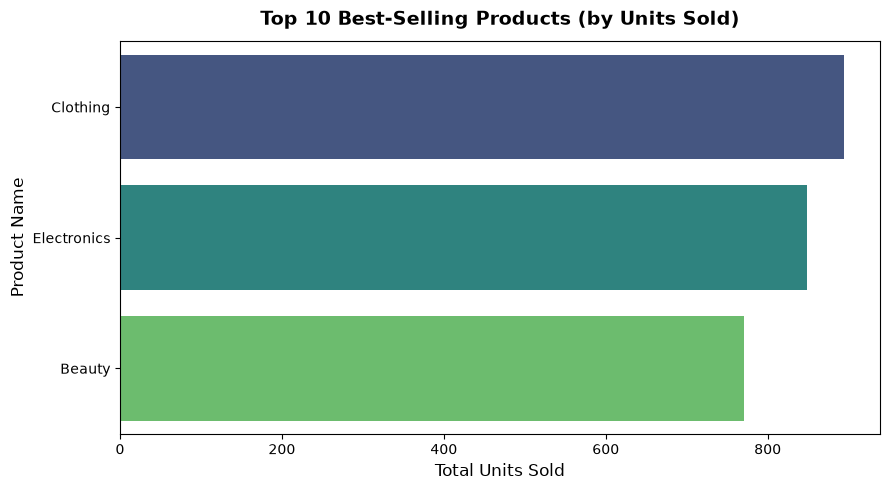

In [36]:
top10_products = df.groupby('Product Category')['Quantity'].sum().nlargest(10).reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=top10_products, y='Product Category', x='Quantity', palette='viridis', hue='Product Category')
plt.title('Top 10 Best-Selling Products (by Units Sold)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Total Units Sold', fontsize=12)
plt.ylabel('Product Name', fontsize=12)
plt.tight_layout()
plt.show()

#### Total Revenue by Product Category Bar Chart

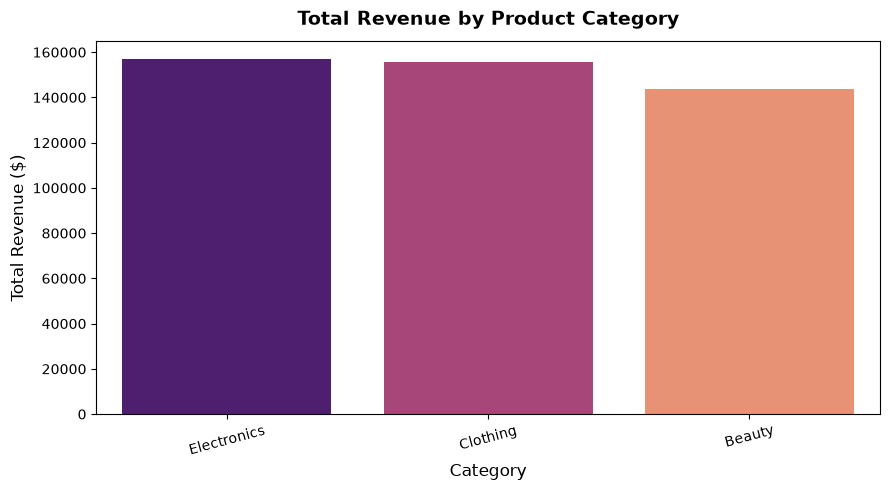

In [38]:
revenue_by_cat = df.groupby('Product Category')['Total Amount'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(data=revenue_by_cat, x='Product Category', y='Total Amount', palette='magma', hue='Product Category')
plt.title('Total Revenue by Product Category', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Category', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Heatmap

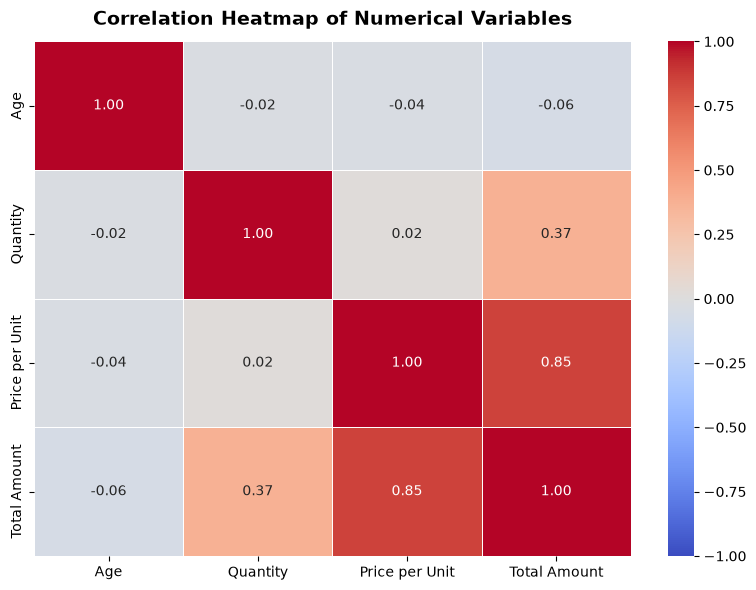

In [39]:
plt.figure(figsize=(8, 6))
num_cols = ['Age', 'Quantity', 'Price per Unit', 'Total Amount']
corr_matrix = df[num_cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Variables', fontsize=14, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

# Additional visualization 
#### Category Revenue Contribution by Age Group using Grouped Bar Chart

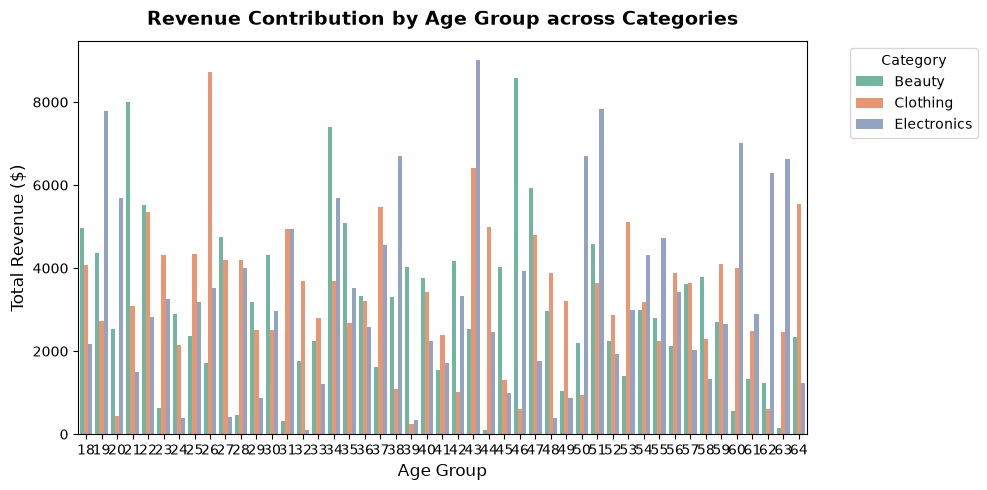

In [40]:
# 8. Category Revenue Contribution by Age Group (Grouped Bar Chart)
plt.figure(figsize=(10, 5))
cat_age_rev = df.groupby(['Age', 'Product Category'], observed=True)['Total Amount'].sum().reset_index()

sns.barplot(data=cat_age_rev, x='Age', y='Total Amount', hue='Product Category', palette='Set2')
plt.title('Revenue Contribution by Age Group across Categories', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Total Revenue ($)', fontsize=12)
plt.legend(title='Category', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Conclusion & Strategic Recommendations

#### 1. Stock up before big sales months
* Finding: The trend charts show exactly which months bring in the most money.
* Action: Order inventory 1 month early so popular items never run out during busy seasons.

#### 2. Target the right products to the right age group

* Finding: The age-by-category chart shows that different age groups prefer different products.
* Action: Show high-end tech/fashion ads to 26–35 year olds, and budget/family deals to other groups.

#### 3. Bundle best-sellers to increase basket size

* Finding: The top-sellers list and correlation heatmap show what people buy most and how much they spend.
* Action: Pair top-selling cheap items with higher-priced products at checkout (like "Frequently Bought Together") to get customers to spend more per visit.